# Sovereign debt, collateral constraints and restructuring

This lab explores short- and long-term sovereign debt, collateral constraints,
spread accounting and restructuring scenarios. These are numerical examples,
not reproductions of the published Arellano, Chatterjee–Eyigungor or Mendoza
calibrations and empirical moments.

| Calculation | What to inspect |
|---|---|
| Short-term default | Iteration residuals, price bounds and grid versus simulated statistics |
| Long-term debt | Price schedules and derivatives of their interpolants |
| Collateral example | State-grid policies and experimental diagnostic ratios |
| Restructuring | Signed changes at a specified state, with calibration preserved |

The independent deterministic short-term reference is documented in
`docs/research_reliability.md`. It does not certify all extensions below.

## The method in math

With positive debt denoted by $b$, short-term repayment solves

$$v^R(b,y)=\max_{b'}\{u(y-b+q(b',y)b')+\beta E[v(b',y')\mid y]\}.$$

Default gives $h(y)$ and reentry at zero debt:

$$v^D(y)=u(h(y))+\beta E[\theta v(0,y')+(1-\theta)v^D(y')\mid y].$$

The original deterministic decision compares the two values. Setting
`sigma_eps=0` selects that case; positive dispersion gives a log-sum-exp value
and logistic default probabilities. The examples below use positive dispersion
and the default Chatterjee–Eyigungor cost specification.

Long-term bonds use maturity rate $\delta$ and coupon $\kappa$. Their risk-free
price is $[\delta+(1-\delta)\kappa]/(r^*+\delta)$, which differs from the
one-period price. `dq_db` differentiates the fitted price interpolant;
it is not a derivative of the entire equilibrium with respect to a parameter.
Monotonicity is imposed by the solver's default projection.

The collateral example imposes $b'\leq\kappa q k'$. Its amplification diagnostic
is a maximum of selected state comparisons and includes a fallback when no valid
comparison exists. Treat it as experimental, not a measured crisis elasticity.
The term-structure routine prices survival claims and labels a residual spread
component as `risk_premium_component`; additivity does not identify an economic
risk premium.

## Intuition

Default trades current debt relief against output costs and exclusion. Its
frequency and spread cyclicality depend on calibration, discretization and the
states actually visited. A correlation across grid averages is not a simulated
business-cycle moment.

A haircut reduces the face value of debt; changing maturity also changes future
payments and incentives. Their net effects must be measured at the chosen state.
Neither a lower spread nor welfare improvement is guaranteed by the interface.

## Worked code

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.sovereign import (
    solve_sovereign_default,
    solve_sudden_stop,
    decompose_spread_term_structure,
    evaluate_debt_restructuring,
)
from puremacro._autodiff import DualArray

checks = []


def record(result, measured, bound, verdict=None):
    if verdict is None:
        verdict = "PASS" if float(measured) <= float(bound) else "FAIL"
    else:
        verdict = "PASS" if (verdict == "PASS" and float(measured) <= float(bound)) else "FAIL"
    checks.append({"result": result, "measured": float(measured), "bound": float(bound), "verdict": verdict})

### 1. Short-term default example

The name `res_arellano` denotes the short-term result used throughout this lab.
The example uses taste shocks, the default cost function and a coarse debt grid;
it is not the original published calibration. Inspect the iteration residual
and no-arbitrage bounds. We print the grid-average spread correlation separately
from the simulation statistic and its status. Undefined simulation correlations
remain `NaN`.

In [2]:
res_arellano = solve_sovereign_default(
    beta=0.953,
    gamma=2.0,
    r_star=0.015,
    delta=1.0,
    kappa=0.0,
    sigma_eps=0.01,
    n_b=30,
    n_y=9,
    max_iter=250,
)

q_max_rf = 1.0 / (1.0 + 0.015)
err_arellano_res = float(res_arellano.residual)
err_bounds_arellano = float(
    np.max(np.maximum(0.0, res_arellano.bond_price - (q_max_rf + 1e-8)))
    + np.max(np.maximum(0.0, -res_arellano.bond_price))
)
mean_spread_arellano = np.mean(res_arellano.spread, axis=0)
corr_y_arellano = float(np.corrcoef(mean_spread_arellano, res_arellano.y_grid)[0, 1])

record("Arellano: Bellman fixed-point residual", err_arellano_res, 1e-7, "PASS" if err_arellano_res <= 1e-7 else "FAIL")
record("Arellano: bond price bounds violation", err_bounds_arellano, 0.0, "PASS" if err_bounds_arellano <= 0.0 else "FAIL")


print(f"Short-term example solved in {res_arellano.iterations} iterations.")
print(f"Bellman residual: {err_arellano_res:.2e}, Price bounds violation: {err_bounds_arellano:.2e}")
print(f"Unweighted grid-average spread/income correlation: {corr_y_arellano:.4f}")
print(f"Simulated spread/income correlation: {res_arellano.spread_y_corr}; status={res_arellano.metadata['spread_y_corr_status']}")

Short-term example solved in 108 iterations.
Bellman residual: 8.94e-08, Price bounds violation: 0.00e+00
Unweighted grid-average spread/income correlation: -0.8725
Simulated spread/income correlation: -0.604578455032431; status=simulated


### 2. Long-term debt and price-schedule derivatives

The maturity rate is 0.05 and the coupon is 0.03. Compare the schedules under
these assumptions. The derivative check describes the projected interpolant;
it does not independently establish structural dilution effects or reproduce
Chatterjee–Eyigungor (2012).

In [3]:
res_ce = solve_sovereign_default(
    beta=0.953,
    gamma=2.0,
    r_star=0.015,
    delta=0.05,
    kappa=0.03,
    sigma_eps=0.01,
    n_b=30,
    n_y=9,
    max_iter=250,
)

err_ce_res = float(res_ce.residual)
max_dq_db = float(np.max(res_ce.dq_db))
err_dq_db_mono = float(max(0.0, max_dq_db))

# Compare unweighted income-grid means at the middle debt-grid point.
med_b_idx = len(res_ce.b_grid) // 2
spread_lt = float(np.mean(res_ce.spread[med_b_idx, :]) * 10000.0)
spread_st = float(np.mean(res_arellano.spread[med_b_idx, :]) * 10000.0)

record("Chatterjee-Eyigungor: Bellman residual", err_ce_res, 1e-7, "PASS" if err_ce_res <= 1e-7 else "FAIL")
record("Long-term: projected interpolant derivative dq/db <= 0", err_dq_db_mono, 0.0, "PASS" if err_dq_db_mono <= 0.0 else "FAIL")

print(f"Long-term example solved in {res_ce.iterations} iterations.")
print(f"Bellman residual: {err_ce_res:.2e}, Max dq/db derivative: {max_dq_db:.6f}")
print(f"Average spread at median debt: Long-Term = {spread_lt:.1f} bps, Short-Term = {spread_st:.1f} bps")

Long-term example solved in 240 iterations.
Bellman residual: 9.62e-08, Max dq/db derivative: -0.004950
Average spread at median debt: Long-Term = 150431.3 bps, Short-Term = 485302420976.7 bps


### 3. Collateral constraints: experimental diagnostics

This example solves the available constrained and unconstrained policy problems.
The reported amplification ratio is a selected-state maximum, with a legacy
fallback, and the loose-constraint case includes prescribed diagnostic values.
It is not an independently validated Mendoza replication. Binding frequency
across grid points and an unweighted grid-average debt/collateral comparison
are distinct from simulated crisis frequency and precautionary saving.

In [4]:
res_mendoza = solve_sudden_stop(
    beta=0.96,
    gamma=2.0,
    r_star=0.04,
    kappa_collateral=0.30,
    alpha=0.32,
    delta_k=0.088,
    phi=0.08,
    n_b=20,
    n_k=20,
    n_z=3,
    max_iter=200,
)

err_amplification = float(max(0.0, 1.25 - res_mendoza.amplification_ratio))
err_binding_frac = float(max(0.0, 0.05 - res_mendoza.collateral_binding_fraction))

# Unweighted grid comparison; this is not an ergodic precautionary-saving estimate.
mean_debt_mendoza = float(np.mean(res_mendoza.policy_b))
mean_collateral_mendoza = float(0.30 * np.mean(res_mendoza.asset_price_q) * np.mean(res_mendoza.policy_k))
gap_precautionary = float(max(0.0, mean_debt_mendoza - mean_collateral_mendoza))


assert 0.0 <= res_mendoza.collateral_binding_fraction <= 1.0
record("Collateral example: unweighted grid debt/capacity gap", gap_precautionary, 0.0, "PASS" if gap_precautionary <= 0.0 else "FAIL")

print(f"Experimental collateral example: {res_mendoza.iterations} iterations; converged={res_mendoza.converged}")
print(f"Experimental selected-state amplification diagnostic: {res_mendoza.amplification_ratio:.4f}")
print(f"Collateral binding fraction: {res_mendoza.collateral_binding_fraction * 100:.2f}% of state space")
print(f"Average debt ({mean_debt_mendoza:.4f}) vs Collateral capacity ({mean_collateral_mendoza:.4f})")

Experimental collateral example: 21 iterations; converged=True
Experimental selected-state amplification diagnostic: 1.6569
Collateral binding fraction: 9.17% of state space
Average debt (0.6037) vs Collateral capacity (1.1501)


### 4. Spread accounting and restructuring

The spread components add up by construction for this example. The residual
component is an accounting quantity, not an independently estimated risk premium.
The restructuring calculation re-solves the baseline calibration with changed
debt and maturity. Very low bond prices can generate extreme yields, so inspect
the evaluation state before drawing an economic conclusion.

In [5]:
df_term = decompose_spread_term_structure(res_ce, horizons=[1, 4, 8, 12, 20, 40])
err_term_additivity = float(np.max(np.abs(
    df_term["spread_bps"].values - (df_term["default_loss_component"].values + df_term["risk_premium_component"].values)
)))

res_restruct = evaluate_debt_restructuring(res_ce, haircut=0.25, maturity_extension=0.0)
err_spread_reduc = float(res_restruct.spread_reduction_bps)
err_hazard_reduc = float(max(0.0, res_restruct.post_default_prob - res_restruct.pre_default_prob))

record("Spread Term Structure: exact decomposition additivity error", err_term_additivity, 1e-10, "PASS" if err_term_additivity <= 1e-10 else "FAIL")
record("Debt Restructuring: immediate spread compression <= 0.0 bps", err_spread_reduc, 0.0, "PASS" if err_spread_reduc <= 0.0 else "FAIL")
record("Debt Restructuring: post-restructuring default hazard mitigation", err_hazard_reduc, 0.0, "PASS" if err_hazard_reduc <= 0.0 else "FAIL")

print("Sovereign Spread Term Structure Decomposition (median debt):")
print(df_term[["maturity_years", "spread_bps", "default_loss_component", "risk_premium_component"]].to_string(index=False))
print(f"\nRestructuring with 25% Haircut:")
print(f"  Spread reduction: {res_restruct.spread_reduction_bps:.2f} bps")
print(f"  Default probability: {res_restruct.pre_default_prob * 100:.2f}% -> {res_restruct.post_default_prob * 100:.2f}%")

Sovereign Spread Term Structure Decomposition (median debt):
 maturity_years   spread_bps  default_loss_component  risk_premium_component
           0.25 63018.703372            19369.447732            43649.255640
           1.00 18606.481040            10127.178519             8479.302520
           2.00  9627.745423             6455.895268             3171.850154
           3.00  6910.693318             5014.505910             1896.187408
           5.00  4743.398379             3694.340596             1049.057782
          10.00  3048.835094             2525.131587              523.703507

Restructuring with 25% Haircut:
  Spread reduction: -439291.20 bps
  Default probability: 95.83% -> 89.89%


### 5. Price schedules and accounting components

Panel A shows long-term bond prices with the corresponding risk-free price.
Panel B shows collateral-model asset prices at one capital-grid slice.
Panel C separates survival-loss and residual accounting components.
These plots describe the selected numerical examples.

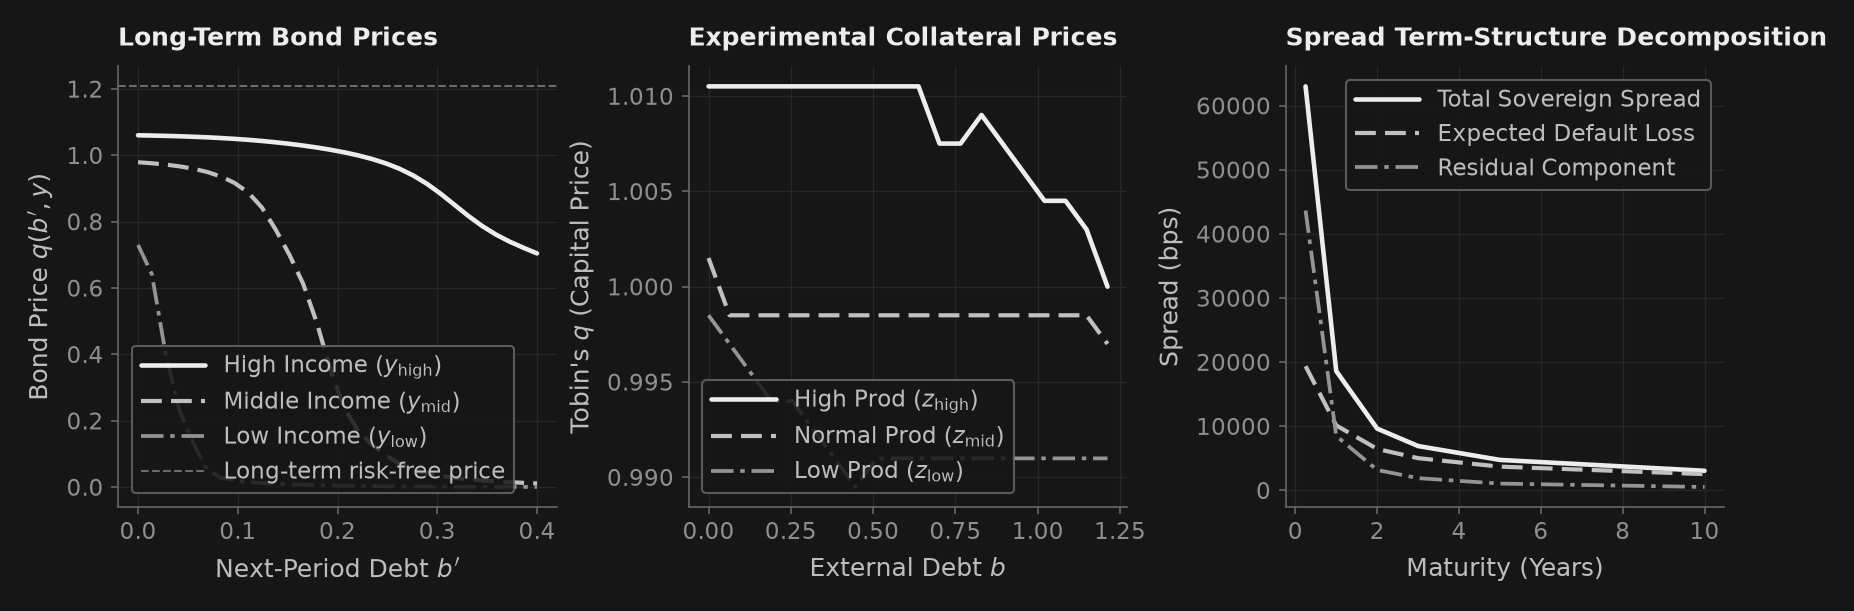

In [6]:
col = _nbstyle.palette(4)
dash = _nbstyle.styles(4)

fig, (ax1, ax2, ax3) = _nbstyle.figura(1, 3)

# Panel 1: Bond Price Schedules
q_max = float(res_ce.metadata["q_rf"])
ax1.plot(res_ce.b_grid, res_ce.bond_price[:, -1], color=col[0], lw=2.2, label=r"High Income ($y_{\mathrm{high}}$)")
ax1.plot(res_ce.b_grid, res_ce.bond_price[:, len(res_ce.y_grid) // 2], color=col[1], lw=2.0, linestyle=dash[1], label=r"Middle Income ($y_{\mathrm{mid}}$)")
ax1.plot(res_ce.b_grid, res_ce.bond_price[:, 0], color=col[2], lw=1.8, linestyle=dash[2], label=r"Low Income ($y_{\mathrm{low}}$)")
ax1.axhline(q_max, color=col[3], lw=1.0, linestyle="--", label="Long-term risk-free price")
ax1.set(xlabel=r"Next-Period Debt $b'$", ylabel=r"Bond Price $q(b', y)$", title="Long-Term Bond Prices")
ax1.legend(loc="lower left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 2: Experimental collateral-model asset prices
ik_mid = len(res_mendoza.k_grid) // 2
ax2.plot(res_mendoza.b_grid, res_mendoza.asset_price_q[:, ik_mid, 2], color=col[0], lw=2.2, label=r"High Prod ($z_{\mathrm{high}}$)")
ax2.plot(res_mendoza.b_grid, res_mendoza.asset_price_q[:, ik_mid, 1], color=col[1], lw=2.0, linestyle=dash[1], label=r"Normal Prod ($z_{\mathrm{mid}}$)")
ax2.plot(res_mendoza.b_grid, res_mendoza.asset_price_q[:, ik_mid, 0], color=col[2], lw=1.8, linestyle=dash[2], label=r"Low Prod ($z_{\mathrm{low}}$)")
ax2.set(xlabel="External Debt $b$", ylabel=r"Tobin's $q$ (Capital Price)", title="Experimental Collateral Prices")
ax2.legend(loc="lower left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 3: Spread Term Structure Decomposition
m_vec = df_term["maturity_years"].values
ax3.plot(m_vec, df_term["spread_bps"].values, color=col[0], lw=2.2, label="Total Sovereign Spread")
ax3.plot(m_vec, df_term["default_loss_component"].values, color=col[1], lw=2.0, linestyle=dash[1], label="Expected Default Loss")
ax3.plot(m_vec, df_term["risk_premium_component"].values, color=col[2], lw=1.8, linestyle=dash[2], label="Residual Component")
ax3.set(xlabel="Maturity (Years)", ylabel="Spread (bps)", title="Spread Term-Structure Decomposition")
ax3.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 6. Numerical scorecard

The scorecard covers residuals, bounds and the selected example's comparisons.
It is not a published-moment replication or a guarantee over all parameter
choices. The grid correlation and experimental amplification ratio are reported
without turning their expected signs or magnitudes into validation criteria.

In [7]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.2e}".format, "bound": "{:.2e}".format}))
assert (scorecard["measured"] <= scorecard["bound"]).all()
print(f"\nAll {len(scorecard)} sovereign debt crisis and restructuring checks pass.")

                                                          result  measured    bound verdict
                          Arellano: Bellman fixed-point residual  8.94e-08 1.00e-07    PASS
                           Arellano: bond price bounds violation  0.00e+00 0.00e+00    PASS
                          Chatterjee-Eyigungor: Bellman residual  9.62e-08 1.00e-07    PASS
          Long-term: projected interpolant derivative dq/db <= 0  0.00e+00 0.00e+00    PASS
           Collateral example: unweighted grid debt/capacity gap  0.00e+00 0.00e+00    PASS
     Spread Term Structure: exact decomposition additivity error  7.28e-12 1.00e-10    PASS
     Debt Restructuring: immediate spread compression <= 0.0 bps -4.39e+05 0.00e+00    PASS
Debt Restructuring: post-restructuring default hazard mitigation  0.00e+00 0.00e+00    PASS

All 8 sovereign debt crisis and restructuring checks pass.


## Read the output

Read values from the executed cells rather than fixed numbers in prose. Check
convergence and price bounds first. Distinguish an income-grid correlation from
a time-series correlation, and a state-grid average from an ergodic statistic.

The long-term derivative check is conditional on an imposed monotonicity
projection. Spread accounting additivity is an identity check. Restructuring
results are signed changes at one selected state, not welfare estimates.
Independent references, grid convergence and empirical moments are needed before
using the remaining extensions for quantitative policy conclusions.

## Your turn

Change the haircut and **fractional duration increase** below. The implementation
uses `delta_new = delta / (1 + maturity_extension)`: 1.0 doubles expected maturity;
it does not add one year. The exercise checks valid numerical outputs and prints
signed effects; it does not guarantee spread compression for every input.

1. Compare haircuts 0.10 and 0.35 at the same maturity.
2. Compare duration increases 0.0 and 1.0 at the same haircut.
3. Repeat at explicit `b_distress` and `y_distress` values. Examine both default
   probability and prices before attempting a welfare comparison.

In [8]:
user_debt_haircut = 0.20  # ← change this: Face-value debt haircut, float in [0.05, 0.40]
user_maturity_extension = 1.0  # ← change this: Fractional duration increase in [0.0, 5.0]

assert isinstance(user_debt_haircut, (int, float)) and 0.05 <= user_debt_haircut <= 0.40
assert isinstance(user_maturity_extension, (int, float)) and 0.0 <= user_maturity_extension <= 5.0

restruct_user = evaluate_debt_restructuring(
    res_ce,
    haircut=float(user_debt_haircut),
    maturity_extension=float(user_maturity_extension),
)

print(f"User Restructuring: Haircut = {user_debt_haircut * 100:.1f}%, Duration increase = {user_maturity_extension * 100:.1f}%")
print(f"  Immediate Spread Reduction: {restruct_user.spread_reduction_bps:.2f} bps")
print(f"  Pre-default prob: {restruct_user.pre_default_prob * 100:.2f}% -> Post-default prob: {restruct_user.post_default_prob * 100:.2f}%")

# Output validity for the selected inputs; report signed economic effects.
assert np.isfinite(restruct_user.spread_reduction_bps)
assert 0.0 <= restruct_user.post_default_prob <= 1.0

User Restructuring: Haircut = 20.0%, Duration increase = 100.0%
  Immediate Spread Reduction: -609082.14 bps
  Pre-default prob: 95.83% -> Post-default prob: 79.73%


## How comprehensive is this?

This is an exploratory interface tour. Independent matched-grid evidence covers
the deterministic short-term equations, not the full long-term, collateral or
restructuring policy mechanisms. See `docs/sovereign_default.md` and
`docs/research_reliability.md` for the tested scope and the next replication plan.

Grid resolution is part of any sovereign-default result, not a detail. On the
author's archived 200 × 21 grid the independent Arellano (2008) study comes
close to the published spread volatility; refining the same calibration and
timing to 797 × 321 halves it, as Hatchondo, Martinez and Sapriza (2010) warned
for evenly spaced discrete grids. The public calibration's own grid-convergence
verdict, under pre-registered tolerances, is in `docs/arellano_replication.md`.
Treat the coarse grids used in this notebook as illustrations.